# India EDA (data for Model 3)

Phase 1 data exploration. Read-only: this notebook does not change anything in `data/`.

**Input:** `data/processed_india/india_monthly_temperature.csv` (built by DVC stage `build_india_monthly` from IMD gridded data).
One row per 1-degree grid cell per month, 1951-2025.
- `tmax_mean`, `tmin_mean`, `tmean_mean`: monthly mean temperature (degC).
- `tmax_days`, `tmin_days`: number of days with data in that month.
- `*_normal`: the cell's own 1961-1990 mean for that calendar month; `*_anom` = value - normal.
- Missing values are real gaps and are **not** filled.

Extra inputs for Section 7: `data/raw/co2_annmean_mlo.txt` (Mauna Loa CO2) and `data/raw/detrend.nino34.ascii.txt` (Nino 3.4).

Figures are saved to `reports/eda_india/`.

In [1]:
# Find the repo root (folder with dvc.yaml) so the notebook works from the root or from notebooks/
import os
from pathlib import Path

_p = Path.cwd().resolve()
while not (_p / "dvc.yaml").exists():
    if _p.parent == _p:
        raise RuntimeError("Could not find repo root (dvc.yaml)")
    _p = _p.parent
os.chdir(_p)
print("Working directory:", Path.cwd())

Working directory: /Users/sarachhabra/Climate-Change-Awareness-Dashboard


In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.tsa.stattools import acf

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid")

FIG_DIR = Path("reports/eda_india")
FIG_DIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path, dpi=120, bbox_inches="tight")
    print("saved", path)

def cell_map(ax, d, col, title, cbar_label="", **kw):
    sc = ax.scatter(d["lon"], d["lat"], c=d[col], marker="s", s=38, **kw)
    ax.set_aspect("equal"); ax.set_title(title)
    ax.set_xlabel("longitude (degrees East)"); ax.set_ylabel("latitude (degrees North)")
    plt.colorbar(sc, ax=ax, shrink=0.8).set_label(cbar_label)
    return sc

SUMMARY = {}
df = pd.read_csv("data/processed_india/india_monthly_temperature.csv", parse_dates=["date"])
cells = df.groupby("cell_id")[["lat", "lon"]].first()

## 1. Overview
Shape, cells, months, missing values per column, missing by year and by cell.

In [3]:
print("shape:", df.shape)
print("cells:", df["cell_id"].nunique(), "| months:", df["date"].nunique(),
      "| period:", df["date"].min().date(), "-", df["date"].max().date())
print("cells x months =", df["cell_id"].nunique() * df["date"].nunique(), "(full grid if equal to rows)")
print("duplicate cell-month rows:", int(df.duplicated(["cell_id", "date"]).sum()))
print("lat range:", cells["lat"].min(), "-", cells["lat"].max(), "| lon range:", cells["lon"].min(), "-", cells["lon"].max())

miss = df.isna().sum().to_frame("missing")
miss["%"] = (100 * miss["missing"] / len(df)).round(2)
print("\nMissing values per column:")
print(miss.to_string())

SUMMARY["Rows / cells / months"] = f"{len(df):,} / {df['cell_id'].nunique()} / {df['date'].nunique()}"
SUMMARY["% tmean_anom missing"] = f"{100 * df['tmean_anom'].isna().mean():.2f}%"

shape: (322200, 17)
cells: 358 | months: 900 | period: 1951-01-01 - 2025-12-01
cells x months = 322200 (full grid if equal to rows)
duplicate cell-month rows: 0
lat range: 8.5 - 36.5 | lon range: 68.5 - 97.5

Missing values per column:
              missing     %
date                0  0.00
year                0  0.00
month               0  0.00
cell_id             0  0.00
lat                 0  0.00
lon                 0  0.00
tmax_mean        7246  2.25
tmin_mean        7227  2.24
tmean_mean       7251  2.25
tmax_days           0  0.00
tmin_days           0  0.00
tmax_normal       300  0.09
tmin_normal       300  0.09
tmean_normal      300  0.09
tmax_anom        7417  2.30
tmin_anom        7398  2.30
tmean_anom       7422  2.30


saved reports/eda_india/01_missing_by_year_and_cell.png


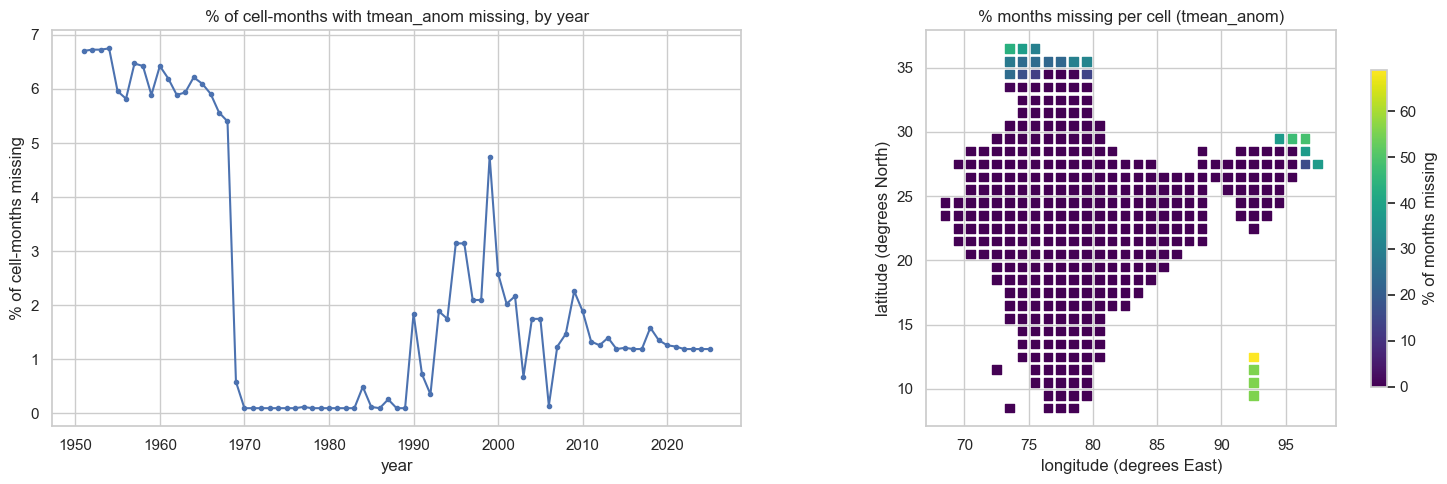

years with the most missing (%):
year
1954    6.75
1953    6.73
1952    6.73
1951    6.70
1957    6.47

cells by % missing:
count    358.00
mean       2.30
std        9.41
min        0.00
25%        0.00
50%        0.00
75%        0.00
max       69.00
cells with 0% missing: 330
cells with 100% missing: 0

worst 8 cells:
           pct_missing   lat   lon
cell_id                           
12.5_92.5        69.00  12.5  92.5
9.5_92.5         55.67   9.5  92.5
11.5_92.5        55.67  11.5  92.5
10.5_92.5        55.67  10.5  92.5
29.5_96.5        48.78  29.5  96.5
29.5_95.5        47.22  29.5  95.5
36.5_73.5        43.67  36.5  73.5
36.5_74.5        38.11  36.5  74.5


In [4]:
by_year = df.groupby("year")["tmean_anom"].apply(lambda s: 100 * s.isna().mean())
by_cell = df.groupby("cell_id")["tmean_anom"].apply(lambda s: 100 * s.isna().mean()).to_frame("pct_missing").join(cells)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(by_year.index, by_year.values, marker=".")
axes[0].set_title("% of cell-months with tmean_anom missing, by year"); axes[0].set_ylabel("% of cell-months missing"); axes[0].set_xlabel("year")
cell_map(axes[1], by_cell, "pct_missing", "% months missing per cell (tmean_anom)", cbar_label="% of months missing", cmap="viridis")
fig.tight_layout()
save(fig, "01_missing_by_year_and_cell"); plt.show()

print("years with the most missing (%):"); print(by_year.sort_values(ascending=False).head(5).round(2).to_string())
print("\ncells by % missing:"); print(by_cell["pct_missing"].describe().round(2).to_string())
print("cells with 0% missing:", int((by_cell["pct_missing"] == 0).sum()))
print("cells with 100% missing:", int((by_cell["pct_missing"] == 100).sum()))
print("\nworst 8 cells:"); print(by_cell.sort_values("pct_missing", ascending=False).head(8).round(2).to_string())

### How to read this graph
**Left panel.** The x-axis is the year. The y-axis is the % of grid-cell months in that year with no mean temperature value.

**Right panel.** This is a map. Each square is one *grid cell*: a 1-degree by 1-degree box (about 110 km on each side) over India. The x-axis is longitude (degrees East) and the y-axis is latitude (degrees North). The colour shows the % of all 900 months with no value: dark purple = 0%, yellow = most missing.

**Worked example.** The yellow square at latitude 12.5, longitude 92.5 (Andaman Islands) has 69.0% missing. For about 7 out of 10 months since 1951 there is no temperature for that box.

**What it shows.**
- Gaps are rare overall: 330 of the 358 cells have no gaps at all.
- The few gappy cells are on the edges: the Andaman & Nicobar islands, the far north-east and the far north.
- By year, the early 1950s are worst (for example 6.75% missing in 1954).

**Why it matters.** For Model 3 we should leave out or flag the gappy edge cells rather than invent values. For the dashboard, island and border cells should be marked as "less data".

**Finding (Overview):**
- 322,200 rows = 358 cells x 900 months (1951-01 to 2025-12), a full grid with no duplicates.
- `tmean_anom` is missing in 2.30% of rows (7,422). The `*_normal` columns are missing in 300 rows, which then also lack an anomaly.
- Missing data is concentrated in a few cells: 330 of 358 cells have 0% missing, and no cell is 100% missing. The worst cells are:
  - Andaman & Nicobar (lon 92.5: 69.0%, 55.67%, 55.67%, 55.67%)
  - far north-east around 29.5N 95.5-96.5E (47-49%)
  - the far north at 36.5N (38-44%)
- By year, the 1950s are worst (about 6.5-6.75% missing).

## 2. Normals (1961-1990)
The normal is the same for every year, so one row per cell per calendar month is enough.

saved reports/eda_india/02_normals_maps.png


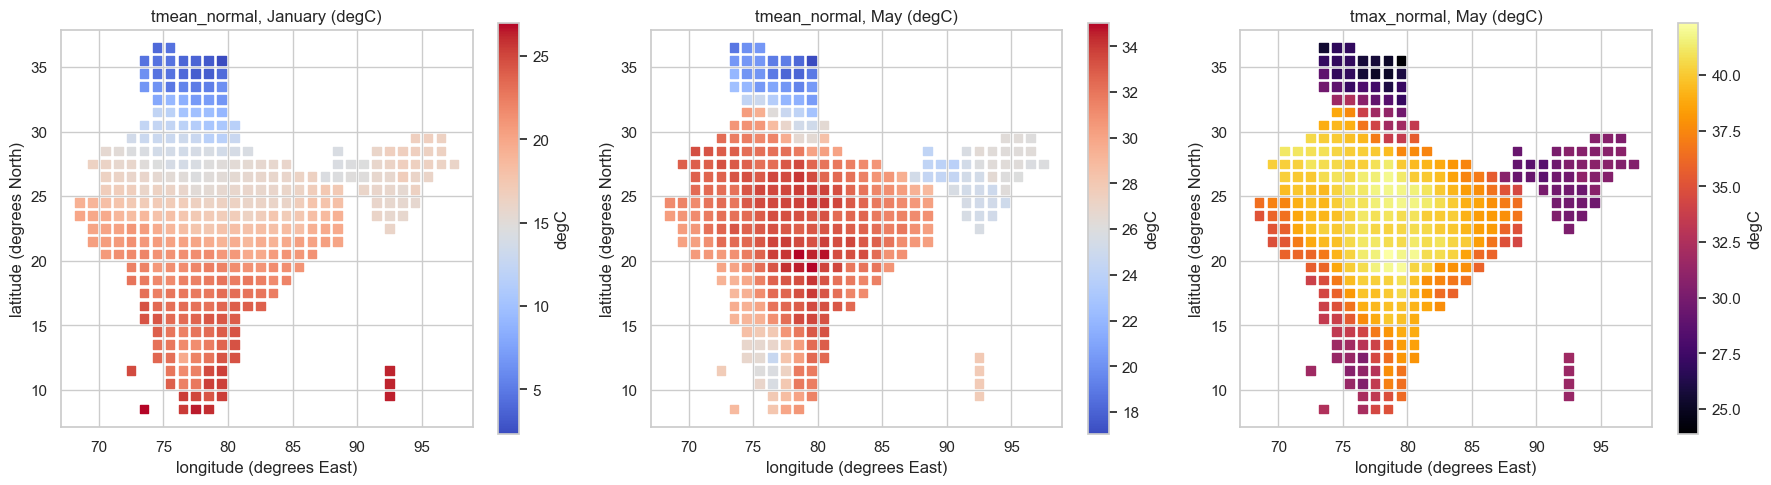

Jan tmean: min 2.3 (35.5_79.5), median 17.4, max 27.0 (8.5_73.5), cells with NaN 2
May tmean: min 17.0 (35.5_79.5), median 31.3, max 35.0 (20.5_78.5), cells with NaN 0
May tmax: min 23.9 (35.5_79.5), median 37.8, max 42.3 (20.5_78.5), cells with NaN 0


In [5]:
norm = df[df["year"] == 1961].set_index(["cell_id", "month"])[["tmean_normal", "tmax_normal"]].join(cells, on="cell_id").reset_index()
jan = norm[norm["month"] == 1]; may = norm[norm["month"] == 5]

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
cell_map(axes[0], jan, "tmean_normal", "tmean_normal, January (degC)", cbar_label="degC", cmap="coolwarm")
cell_map(axes[1], may, "tmean_normal", "tmean_normal, May (degC)", cbar_label="degC", cmap="coolwarm")
cell_map(axes[2], may, "tmax_normal", "tmax_normal, May (degC)", cbar_label="degC", cmap="inferno")
fig.tight_layout()
save(fig, "02_normals_maps"); plt.show()

for name, d, c in [("Jan tmean", jan, "tmean_normal"), ("May tmean", may, "tmean_normal"), ("May tmax", may, "tmax_normal")]:
    s = d.set_index("cell_id")[c]
    print(f"{name}: min {s.min():.1f} ({s.idxmin()}), median {s.median():.1f}, max {s.max():.1f} ({s.idxmax()}), cells with NaN {int(s.isna().sum())}")

### How to read this graph
Three maps of India; each square is one 1-degree grid cell (x = longitude, y = latitude). The colour is the *normal* temperature in degC. The normal is the cell's average over 1961-1990 for that calendar month, so it describes a typical January or May, not one particular year.
- Left: mean temperature, January.
- Middle: mean temperature, May.
- Right: daily maximum temperature, May.

**Worked example.** The darkest-blue square in the January map, at 35.5N 79.5E (Ladakh, high Himalaya), has a January normal of 2.3 degC. A typical January there averages just above freezing over day and night.

**What it shows.**
- In January the north is cold and the south warm (2.3 to 27.0 degC, median 17.4).
- May is hot almost everywhere (median 31.3 degC).
- Central India at 20.5N 78.5E is the hottest: a May mean of 35.0 degC and a May daily maximum of 42.3 degC.

**Why it matters.** All our anomalies are measured against these normals, so they are the "zero line" for Model 3 and for every warming map on the dashboard.

**Finding (Normals):** The 1961-1990 normals show the expected geography.
- January tmean ranges from 2.3 degC (35.5N 79.5E, Ladakh) to 27.0 degC (8.5N 73.5E, far south-west), median 17.4.
- May is the hottest pre-monsoon month: tmean median 31.3 degC (max 35.0 at 20.5N 78.5E, central India / Vidarbha). tmax median 37.8, max 42.3 degC in the same cell.
- 2 cells have no January normal. The 300 missing normal rows equal 4 cell-calendar-months x 75 years; the other 2 cell-months were not identified here.

## 3. All-India anomaly
All-India value = simple mean over the cells that have data that month (**not** area-weighted).
At 1 degree a cell at 36N is about cos(36)/cos(8.5) = 0.82 times the area of one at 8.5N, so we also compute a
cos(latitude)-weighted mean to see how much that matters.

In [6]:
d = df.dropna(subset=["tmean_anom"]).copy()
d["w"] = np.cos(np.deg2rad(d["lat"]))
monthly = d.groupby("date")["tmean_anom"].mean()
d["wx"] = d["w"] * d["tmean_anom"]
monthly_w = d.groupby("date")["wx"].sum() / d.groupby("date")["w"].sum()
n_cells = d.groupby("date").size()
print("months:", len(monthly), "| cells per month min/median/max:", n_cells.min(), int(n_cells.median()), n_cells.max())

diff_w = monthly_w - monthly
print(f"weighted - unweighted monthly: mean {diff_w.mean():+.4f}, max |diff| {diff_w.abs().max():.4f} degC, r = {np.corrcoef(monthly, monthly_w)[0,1]:.5f}")

annual = monthly.groupby(monthly.index.year).mean()
annual_w = monthly_w.groupby(monthly_w.index.year).mean()
months_per_year = monthly.groupby(monthly.index.year).size()
print("years with < 12 months of all-India data:", months_per_year[months_per_year < 12].to_dict())
print(f"annual: weighted - unweighted max |diff| {(annual_w - annual).abs().max():.4f} degC")
roll = annual.rolling(10, center=True).mean()

s, i, r, p, se = stats.linregress(annual.index, annual.values)
print(f"\nAll-India annual tmean_anom trend 1951-2025: {s*10:+.3f} degC/decade (p = {p:.1e})")
print("warmest 5 years:"); print(annual.sort_values(ascending=False).head(5).round(3).to_string())
print("coldest 3 years:"); print(annual.sort_values().head(3).round(3).to_string())
SUMMARY["All-India tmean_anom trend (degC/decade)"] = round(s * 10, 3)
SUMMARY["Warmest year (anom degC)"] = f"{annual.idxmax()} ({annual.max():+.2f})"

months: 900 | cells per month min/median/max: 330 353 358
weighted - unweighted monthly: mean -0.0024, max |diff| 0.0748 degC, r = 0.99976
years with < 12 months of all-India data: {}
annual: weighted - unweighted max |diff| 0.0173 degC

All-India annual tmean_anom trend 1951-2025: +0.081 degC/decade (p = 5.3e-08)
warmest 5 years:
date
2009    0.899
2016    0.889
2010    0.870
2024    0.806
2017    0.689
coldest 3 years:
date
1971   -0.500
1975   -0.352
1983   -0.329


saved reports/eda_india/03_all_india_anomaly.png


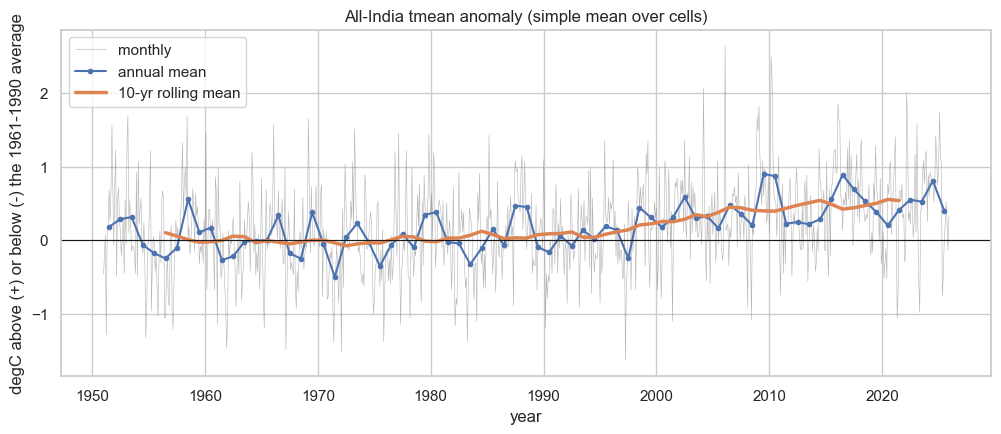

           mean tmean_anom (degC)  years
1951-1960                   0.101     10
1961-1970                  -0.029     10
1971-1980                   0.004     10
1981-1990                   0.022     10
1991-2000                   0.113     10
2001-2010                   0.448     10
2011-2020                   0.421     10
2021-2025                   0.537      5


In [7]:
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(monthly.index, monthly.values, lw=0.4, color="grey", alpha=0.6, label="monthly")
ax.plot(pd.to_datetime(annual.index.astype(str) + "-07-01"), annual.values, marker="o", ms=3, label="annual mean")
ax.plot(pd.to_datetime(roll.index.astype(str) + "-07-01"), roll.values, lw=2.5, label="10-yr rolling mean")
ax.axhline(0, color="k", lw=0.8)
ax.set_xlabel("year"); ax.set_ylabel("degC above (+) or below (-) the 1961-1990 average"); ax.set_title("All-India tmean anomaly (simple mean over cells)"); ax.legend()
save(fig, "03_all_india_anomaly"); plt.show()

dec = pd.cut(annual.index, bins=list(range(1950, 2021, 10)) + [2025], labels=None)
decade_tab = annual.groupby(dec, observed=True).agg(["mean", "count"]).round(3)
decade_tab.index = [f"{int(iv.left)+1}-{int(iv.right)}" for iv in decade_tab.index]
decade_tab.columns = ["mean tmean_anom (degC)", "years"]
print(decade_tab.to_string())
SUMMARY["Decade mean 1951-1960 / 2021-2025"] = f"{decade_tab.iloc[0,0]:+.2f} / {decade_tab.iloc[-1,0]:+.2f}"

### How to read this graph
**Axes.** The x-axis is the year. The y-axis is the *anomaly* in degC: how much warmer (+) or colder (-) a period was than the 1961-1990 normal for that place and month. The value is averaged over all grid cells.
- The thin grey line is every month.
- The dots are yearly averages.
- The thick line is the 10-year rolling mean (the average of the 10 years around each point), which shows the slow trend.

**Worked example.** The highest yearly dot is 2009 at +0.899. Averaged over India and the whole year, 2009 was about 0.9 degC warmer than a typical 1961-1990 year. The lowest is 1971 at -0.500.

**What it shows.**
- India warmed by +0.081 degC per decade over 1951-2025.
- Most of the warming came late. Decade averages are near zero until the 1980s (+0.10, -0.03, +0.00, +0.02), then rise to +0.45 (2001-2010) and +0.54 (2021-2025).
- Giving cells weights by their true area changes yearly values by at most 0.017 degC, so a simple average is fine.

**Why it matters.** This line is the main target for Model 3 and the headline chart for the dashboard. A model must capture the faster warming after about 1990, not just a straight line.

**Finding (All-India anomaly):**
- Every month has data for 330-358 cells (median 353), so all 75 years have 12 months.
- **Area weighting barely matters at 1 degree:** cos(lat)-weighted vs simple mean differ by at most 0.075 degC per month and 0.017 degC per year (r = 0.99976).
- Linear trend 1951-2025: +0.081 degC/decade (p = 5.3e-08).
- Warming is not steady. Decade means are about flat from the 1950s to the 1980s (+0.10, -0.03, +0.00, +0.02 degC), then rise to +0.11 (1991-2000), +0.45 (2001-2010), +0.42 (2011-2020) and +0.54 (2021-2025, 5 years only).
- Warmest years: 2009 (+0.90), 2016 (+0.89), 2010 (+0.87), 2024 (+0.81). Coldest: 1971 (-0.50).

## 4. Decade maps of tmean_anom
Mean over all available months in each period, same colour scale for all three maps.

saved reports/eda_india/04_decade_maps.png


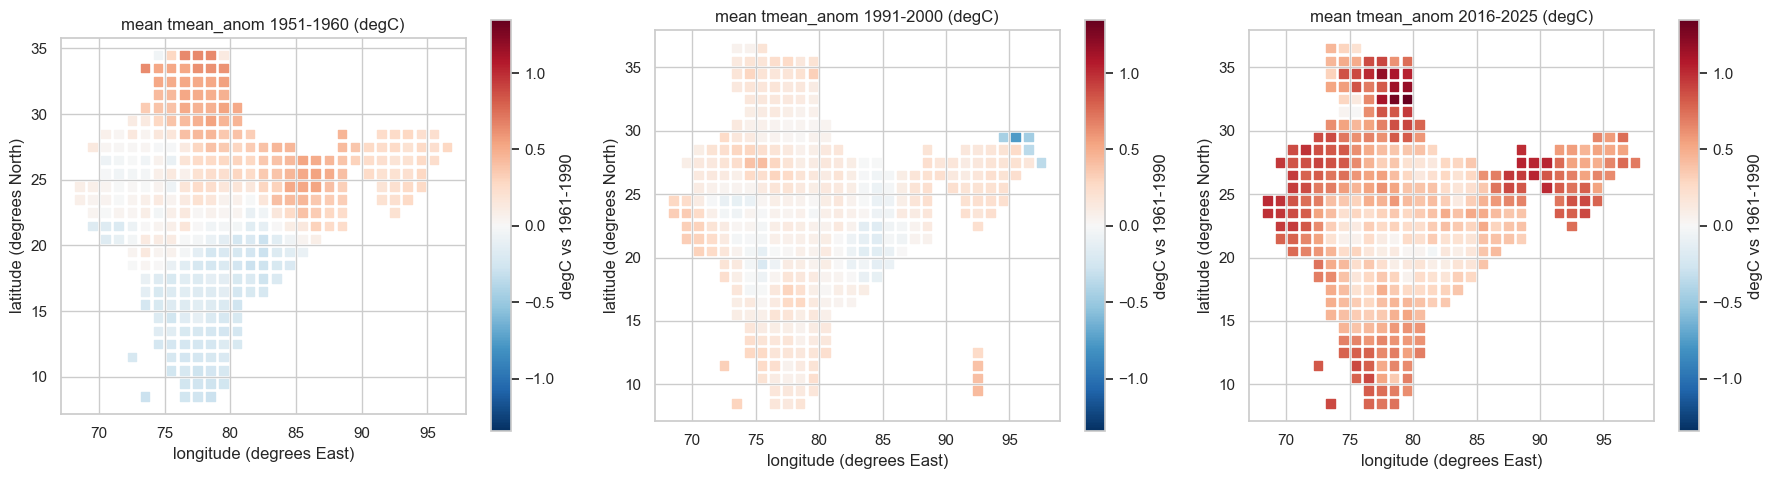

       1951-1960  1991-2000  2016-2025
count     338.00     358.00     354.00
mean        0.10       0.11       0.54
std         0.26       0.13       0.27
min        -0.29      -0.76      -0.03
25%        -0.15       0.05       0.33
50%         0.08       0.12       0.51
75%         0.29       0.18       0.75
max         0.65       0.42       1.35
1951-1960: share of cells warmer than normal = 58% | warmest cell 34.5_77.5 (+0.65) | coldest cell 8.5_73.5 (-0.29)
1991-2000: share of cells warmer than normal = 84% | warmest cell 9.5_92.5 (+0.42) | coldest cell 29.5_95.5 (-0.76)
2016-2025: share of cells warmer than normal = 99% | warmest cell 32.5_79.5 (+1.35) | coldest cell 20.5_81.5 (-0.03)

example cell 28.5_77.5 (near Delhi): {'1951-1960': 0.44, '1991-2000': 0.14, '2016-2025': 0.42}


In [8]:
PERIODS = [(1951, 1960), (1991, 2000), (2016, 2025)]
maps = {}
for a, b in PERIODS:
    maps[f"{a}-{b}"] = df[df["year"].between(a, b)].groupby("cell_id")["tmean_anom"].mean()
mp = pd.DataFrame(maps).join(cells)
lim = np.nanmax(np.abs(mp[list(maps)].values))
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, k in zip(axes, maps):
    cell_map(ax, mp, k, f"mean tmean_anom {k} (degC)", cbar_label="degC vs 1961-1990", cmap="RdBu_r", vmin=-lim, vmax=lim)
fig.tight_layout()
save(fig, "04_decade_maps"); plt.show()
print(mp[list(maps)].describe().round(2).to_string())
for k in maps:
    print(f"{k}: share of cells warmer than normal = {100 * (mp[k] > 0).mean():.0f}% | "
          f"warmest cell {mp[k].idxmax()} ({mp[k].max():+.2f}) | coldest cell {mp[k].idxmin()} ({mp[k].min():+.2f})")
print("\nexample cell 28.5_77.5 (near Delhi):", mp.loc["28.5_77.5", list(maps)].round(2).to_dict())

### How to read this graph
Three maps of India for three periods (1951-1960, 1991-2000, 2016-2025). Each square is a grid cell, coloured by its average anomaly in degC for that period: red = warmer than 1961-1990, blue = colder, white = about the same. All three maps use the same colour scale, so colours can be compared directly.

**Worked example.** The cell at 28.5N 77.5E (near Delhi) is +0.44 degC in 1951-1960, +0.14 in 1991-2000 and +0.42 in 2016-2025. So this one cell was already warm in the 1950s, not only recently.

**What it shows.**
- The share of cells warmer than normal grows from 58% (1951-1960) to 84% (1991-2000) to 99% (2016-2025).
- The warmest cell in 2016-2025 is 32.5N 79.5E (+1.35 degC).
- The strong blue in 1991-2000 at 29.5N 95.5E (-0.76) is in a cell with about 47% of months missing, so treat it with care.

**Why it matters.** For the dashboard, this is a clear "India is turning red" picture. For Model 3, it shows that the warming pattern differs by place and changes over time.

**Finding (Decade maps):**
- Share of cells warmer than their 1961-1990 normal: 58% (1951-1960), 84% (1991-2000), 99% (2016-2025).
- Median cell anomaly: +0.08, +0.12, +0.51 degC. In 2016-2025 the hottest cell is +1.35 and the coldest -0.03.
- 1951-1960 has only 338 cells with data (some cells have no 1950s data).

## 5. Trend per cell
Annual mean anomaly per cell, using only **complete years** (12 months with data for that variable).
Linear trend (degC/decade) for cells with >= 60 complete years.

cells with >= 60 complete years: 335 of 358
count    335.000
mean       0.081
std        0.044
min       -0.009
25%        0.048
50%        0.079
75%        0.115
max        0.172
cells warming: 328; cooling: 7; significant warming (p<0.05): 271; significant cooling: 0


saved reports/eda_india/05_cell_trend_map.png


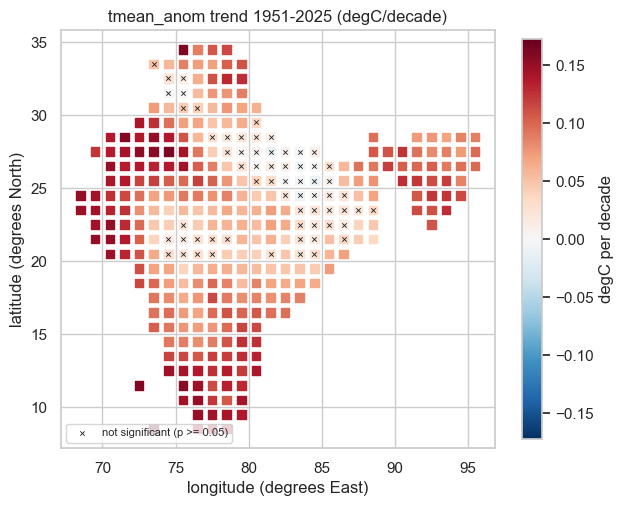


10 fastest-warming cells:
            lat   lon  years  trend_per_decade    p
cell_id                                            
8.5_73.5    8.5  73.5     75             0.172  0.0
27.5_74.5  27.5  74.5     75             0.163  0.0
34.5_75.5  34.5  75.5     61             0.161  0.0
11.5_72.5  11.5  72.5     75             0.160  0.0
28.5_71.5  28.5  71.5     75             0.160  0.0
11.5_75.5  11.5  75.5     75             0.155  0.0
27.5_73.5  27.5  73.5     75             0.155  0.0
27.5_72.5  27.5  72.5     75             0.152  0.0
21.5_69.5  21.5  69.5     75             0.152  0.0
22.5_70.5  22.5  70.5     75             0.152  0.0

5 cells with the lowest trend:
            lat   lon  years  trend_per_decade      p
cell_id                                              
25.5_84.5  25.5  84.5     75            -0.009  0.686
27.5_81.5  27.5  81.5     75            -0.009  0.682
24.5_83.5  24.5  83.5     75            -0.008  0.691
26.5_83.5  26.5  83.5     75            -0.005 

In [9]:
def cell_trends(var, min_years=60):
    g = df.dropna(subset=[var]).groupby(["cell_id", "year"])[var].agg(["mean", "count"])
    g = g[g["count"] == 12]["mean"].reset_index()
    rows = []
    for cid, gg in g.groupby("cell_id"):
        if len(gg) >= min_years:
            r = stats.linregress(gg["year"], gg["mean"])
            rows.append({"cell_id": cid, "years": len(gg), "trend_per_decade": r.slope * 10, "p": r.pvalue})
    return pd.DataFrame(rows).set_index("cell_id").join(cells)

tr = cell_trends("tmean_anom")
print(f"cells with >= 60 complete years: {len(tr)} of {len(cells)}")
print(tr["trend_per_decade"].describe().round(3).to_string())
print(f"cells warming: {int((tr['trend_per_decade'] > 0).sum())}; cooling: {int((tr['trend_per_decade'] < 0).sum())}; "
      f"significant warming (p<0.05): {int(((tr['trend_per_decade'] > 0) & (tr['p'] < 0.05)).sum())}; "
      f"significant cooling: {int(((tr['trend_per_decade'] < 0) & (tr['p'] < 0.05)).sum())}")
SUMMARY["Cells with trend (>=60 complete yrs)"] = len(tr)
SUMMARY["Median cell trend tmean (degC/decade)"] = round(tr["trend_per_decade"].median(), 3)

lim = tr["trend_per_decade"].abs().max()
fig, ax = plt.subplots(figsize=(7, 6.5))
cell_map(ax, tr, "trend_per_decade", "tmean_anom trend 1951-2025 (degC/decade)", cbar_label="degC per decade", cmap="RdBu_r", vmin=-lim, vmax=lim)
sig = tr[tr["p"] >= 0.05]
ax.scatter(sig["lon"], sig["lat"], marker="x", s=10, c="k", lw=0.6, label="not significant (p >= 0.05)")
ax.legend(loc="lower left", fontsize=8)
save(fig, "05_cell_trend_map"); plt.show()

print("\n10 fastest-warming cells:")
print(tr.sort_values("trend_per_decade", ascending=False).head(10)[["lat", "lon", "years", "trend_per_decade", "p"]].round(3).to_string())
print("\n5 cells with the lowest trend:")
print(tr.sort_values("trend_per_decade").head(5)[["lat", "lon", "years", "trend_per_decade", "p"]].round(3).to_string())

### How to read this graph
A map of India; each square is a grid cell (x = longitude, y = latitude). The colour is that cell's warming rate in degC per decade, worked out from a straight line through its yearly anomalies from 1951 to 2025. Red = warming, blue = cooling, white = no change.

**The black x marks.** A small x means the trend is *not significant*: p >= 0.05, so the change could plausibly be chance. Cells without an x have a trend unlikely to be chance. Only cells with at least 60 complete years are shown (335 of 358).

**Worked example.** The darkest red square at 8.5N 73.5E (roughly the Lakshadweep islands, Arabian Sea) has +0.172 degC per decade. Over 75 years that adds up to about 1.3 degC (0.172 x 7.5 decades).

**What it shows.**
- Almost everywhere is warming: 328 cells warm, and 271 of them significantly.
- The fastest warming is in the west (Rajasthan, Gujarat), the far south-west islands and Kashmir.
- A band across eastern Uttar Pradesh and Bihar shows almost no trend (lowest -0.009, p = 0.686). Most of those cells carry an x.

**Why it matters.** A single all-India number hides big local differences. A per-cell Model 3 or a dashboard map should show this, and should not claim warming where the trend is not significant.

cells with >=60 complete years for both tmax and tmin: 335
          tmax     tmin
count  335.000  335.000
mean     0.085    0.076
std      0.067    0.057
min     -0.054   -0.058
25%      0.032    0.034
50%      0.092    0.070
75%      0.136    0.112
max      0.240    0.246
cells where tmin warms faster than tmax: 150 of 335
All-India tmax_anom: +0.088 degC/decade (p = 5.2e-07)
All-India tmin_anom: +0.075 degC/decade (p = 1.0e-05)


All-India tmean_anom: +0.081 degC/decade (p = 5.3e-08)


saved reports/eda_india/05_tmax_vs_tmin_trend_maps.png


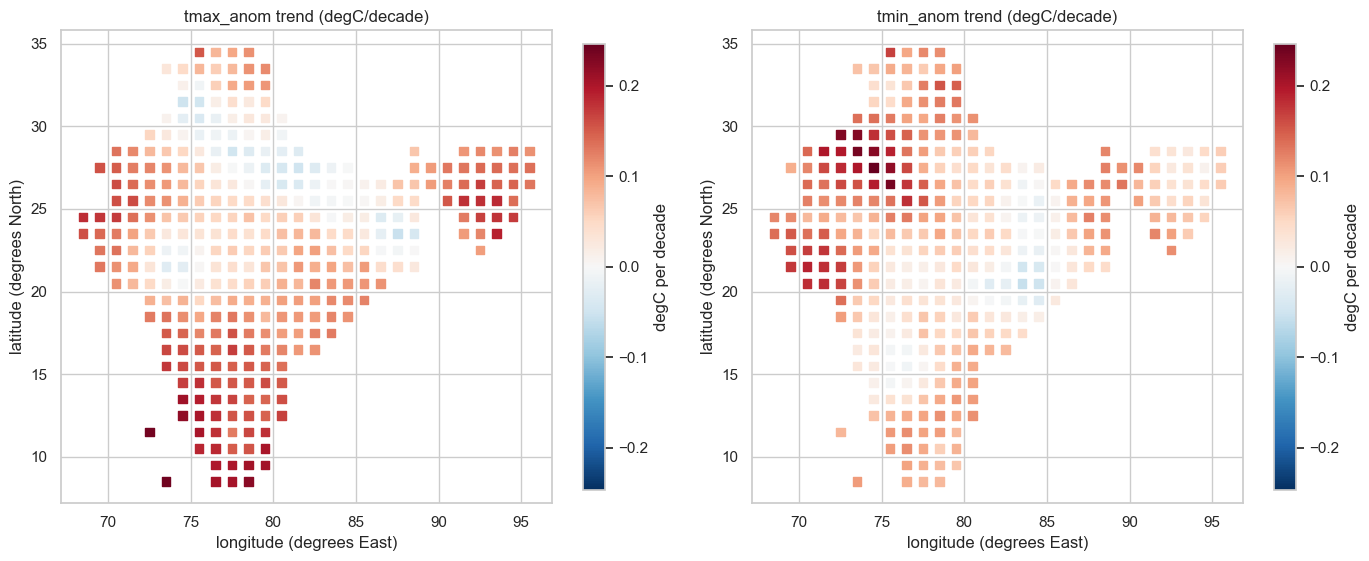

fastest tmax cell: 8.5_73.5 {'tmax': 0.24, 'tmin': 0.104}
fastest tmin cell: 27.5_74.5 {'tmax': 0.079, 'tmin': 0.246}


In [10]:
tr_max = cell_trends("tmax_anom"); tr_min = cell_trends("tmin_anom")
both = tr_max[["trend_per_decade"]].rename(columns={"trend_per_decade": "tmax"}).join(
    tr_min[["trend_per_decade"]].rename(columns={"trend_per_decade": "tmin"}), how="inner").join(cells)
print(f"cells with >=60 complete years for both tmax and tmin: {len(both)}")
print(both[["tmax", "tmin"]].describe().round(3).to_string())
print(f"cells where tmin warms faster than tmax: {int((both['tmin'] > both['tmax']).sum())} of {len(both)}")

# all-India series for tmax and tmin
ai = {}
for v in ["tmax_anom", "tmin_anom", "tmean_anom"]:
    mm = df.dropna(subset=[v]).groupby("date")[v].mean()
    yy = mm.groupby(mm.index.year).mean()
    r = stats.linregress(yy.index, yy.values)
    ai[v] = (r.slope * 10, r.pvalue)
    print(f"All-India {v}: {r.slope*10:+.3f} degC/decade (p = {r.pvalue:.1e})")
SUMMARY["All-India tmax / tmin trend (degC/decade)"] = f"{ai['tmax_anom'][0]:+.3f} / {ai['tmin_anom'][0]:+.3f}"

lim = np.nanmax(np.abs(both[["tmax", "tmin"]].values))
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
cell_map(axes[0], both, "tmax", "tmax_anom trend (degC/decade)", cbar_label="degC per decade", cmap="RdBu_r", vmin=-lim, vmax=lim)
cell_map(axes[1], both, "tmin", "tmin_anom trend (degC/decade)", cbar_label="degC per decade", cmap="RdBu_r", vmin=-lim, vmax=lim)
fig.tight_layout()
save(fig, "05_tmax_vs_tmin_trend_maps"); plt.show()
print("fastest tmax cell:", both["tmax"].idxmax(), both.loc[both["tmax"].idxmax(), ["tmax", "tmin"]].round(3).to_dict())
print("fastest tmin cell:", both["tmin"].idxmax(), both.loc[both["tmin"].idxmax(), ["tmax", "tmin"]].round(3).to_dict())

### How to read this graph
Two maps of India, same layout as the trend map above. Left: warming rate of the daily *maximum* temperature (daytime high). Right: warming rate of the daily *minimum* temperature (night-time low). The colour is degC per decade, and both maps share one colour scale.

**Worked example.** The cell at 27.5N 74.5E (Rajasthan) is dark red on the right map (night lows +0.246 degC/decade) but pale on the left (daytime highs +0.079). Nights there are warming about three times faster than days.

**What it shows.** Across India, daytime highs warm slightly faster (+0.088 degC/decade) than night lows (+0.075). Night lows warm faster in 150 of 335 cells, less than half. The two maps have quite different patterns. For example, at the Lakshadweep cell 8.5N 73.5E daytime highs warm at +0.24 and night lows at +0.104.

**Why it matters.** Days and nights are warming differently in different places, so Model 3 may need separate targets for max and min. For the dashboard, heat-stress messages (hot days) and warm-night messages need different maps.

**Finding (Per-cell trends):**
- 335 of 358 cells have >= 60 complete years. 328 of them warm, 7 cool, and 271 warm significantly (p < 0.05). None cool significantly.
- Median cell trend: +0.079 degC/decade (range -0.009 to +0.172).
- Fastest-warming cells (rough regions read from lat/lon, *not verified against a map*):
  - 8.5N 73.5E (+0.172) and 11.5N 72.5E (+0.160): Lakshadweep, Arabian Sea
  - 27.5N 74.5E, 28.5N 71.5E, 27.5N 73.5E, 27.5N 72.5E (+0.152 to +0.163): western Rajasthan / Thar
  - 34.5N 75.5E (+0.161, 61 years): Kashmir
  - 11.5N 75.5E (+0.155): northern Kerala coast
  - 21.5N 69.5E and 22.5N 70.5E (+0.152): Saurashtra, Gujarat
- The lowest trends (about 0, not significant) are at 24.5-27.5N, 81.5-84.5E: eastern Uttar Pradesh / Bihar, Indo-Gangetic plain.
- **tmax vs tmin:** the all-India trend is +0.088 (tmax) vs +0.075 (tmin) degC/decade. tmin warms faster than tmax in only 150 of 335 cells. Here days warm slightly faster than nights, which goes against the common assumption.

## 6. Seasonal trends (all-India mean)
Seasons: DJF (December counted with the following year's Jan-Feb), MAM, JJAS (monsoon), ON (post-monsoon).
A season-year is used only if all its months are present.

            years   n  trend degC/decade       p
season                                          
DJF     1952-2025  74             0.0707  0.0061
MAM     1951-2025  75             0.0688  0.0174
JJAS    1951-2025  75             0.0750  0.0000
ON      1951-2025  75             0.1270  0.0000


saved reports/eda_india/06_seasonal_trends.png


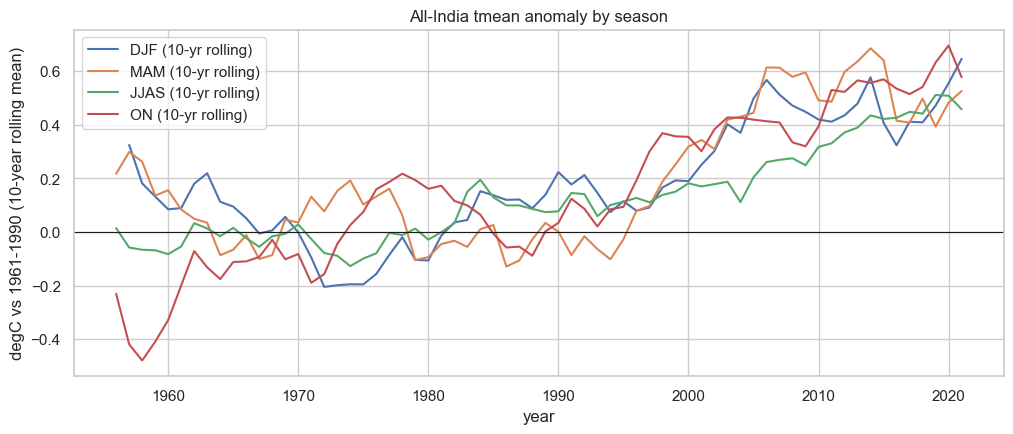

DJF: rolling mean first 1957 = +0.325, last 2021 = +0.646 degC
MAM: rolling mean first 1956 = +0.217, last 2021 = +0.526 degC
JJAS: rolling mean first 1956 = +0.015, last 2021 = +0.458 degC
ON: rolling mean first 1956 = -0.230, last 2021 = +0.578 degC


In [11]:
m = monthly.to_frame("anom")
m["year"] = m.index.year; m["month"] = m.index.month
SEASONS = {"DJF": [12, 1, 2], "MAM": [3, 4, 5], "JJAS": [6, 7, 8, 9], "ON": [10, 11]}
m["season_year"] = np.where(m["month"] == 12, m["year"] + 1, m["year"])
rows, series = [], {}
for sname, months in SEASONS.items():
    x = m[m["month"].isin(months)].groupby("season_year")["anom"].agg(["mean", "count"])
    x = x[x["count"] == len(months)]["mean"]
    series[sname] = x
    r = stats.linregress(x.index, x.values)
    rows.append({"season": sname, "years": f"{x.index.min()}-{x.index.max()}", "n": len(x),
                 "trend degC/decade": r.slope * 10, "p": r.pvalue})
seas = pd.DataFrame(rows).set_index("season")
print(seas.round(4).to_string())
for sname in seas.index:
    SUMMARY[f"Season trend {sname} (degC/decade)"] = round(seas.loc[sname, "trend degC/decade"], 3)

fig, ax = plt.subplots(figsize=(12, 4.5))
for sname, x in series.items():
    ax.plot(x.index, x.rolling(10, center=True).mean(), label=f"{sname} (10-yr rolling)")
ax.axhline(0, color="k", lw=0.8); ax.set_xlabel("year"); ax.set_ylabel("degC vs 1961-1990 (10-year rolling mean)")
ax.set_title("All-India tmean anomaly by season"); ax.legend()
save(fig, "06_seasonal_trends"); plt.show()
for sname, x in series.items():
    rr = x.rolling(10, center=True).mean().dropna()
    print(f"{sname}: rolling mean first {rr.index[0]} = {rr.iloc[0]:+.3f}, last {rr.index[-1]} = {rr.iloc[-1]:+.3f} degC")

### How to read this graph
**Axes.** The x-axis is the year. The y-axis is the all-India anomaly in degC, smoothed with a 10-year rolling mean so the slow change is visible. Each line is one season:
- DJF = December-February (winter)
- MAM = March-May (pre-monsoon summer)
- JJAS = June-September (monsoon)
- ON = October-November (post-monsoon)

**Worked example.** The ON line starts at -0.230 in 1956 and ends at +0.578 in 2021. October-November in the decade around 2021 averaged about 0.6 degC above normal, while in the 1950s it was about 0.2 degC below normal.

**What it shows.** Every season has warmed. The post-monsoon season warmed fastest: +0.127 degC per decade, against +0.069 to +0.075 for the other three. Winter (DJF) was already warm in the 1950s (+0.325 at the start) and ends highest (+0.646).

**Why it matters.** Warming depends on the time of year, so Model 3 should know the month or season. The dashboard can highlight October-November as the fastest-changing season.

**Finding (Seasons):** All four seasons warm significantly (p < 0.05).

| Season | Trend (degC/decade) | p |
|---|---|---|
| ON (post-monsoon) | +0.127 | < 0.0001 |
| JJAS (monsoon) | +0.075 | < 0.0001 |
| DJF | +0.071 | 0.006 |
| MAM | +0.069 | 0.017 |

The post-monsoon (October-November) season warms fastest, about 1.7x the others. DJF has 74 season-years (1952-2025), because Dec 1950 is not in the data.

## 7. Drivers: CO2 and El Nino
Annual all-India tmean_anom vs Mauna Loa annual CO2 (from 1959) and vs the calendar-year mean of the Nino 3.4
`ANOM` column (full 12-month years only). Raw correlations, correlations after removing a linear trend from both
series, and Nino lagged by 1 year.

CO2 years: 1959 - 2025 | Nino full years: 1950 - 2025
                 years   n   r raw   p raw  r detrended  p detrended
driver                                                              
co2_ppm      1959-2025  67  0.6692  0.0000       0.2030       0.0994
nino34       1951-2025  75  0.1668  0.1526       0.2408       0.0374
nino34_lag1  1951-2025  75  0.2437  0.0351       0.3027       0.0083


saved reports/eda_india/07_drivers_scatter.png


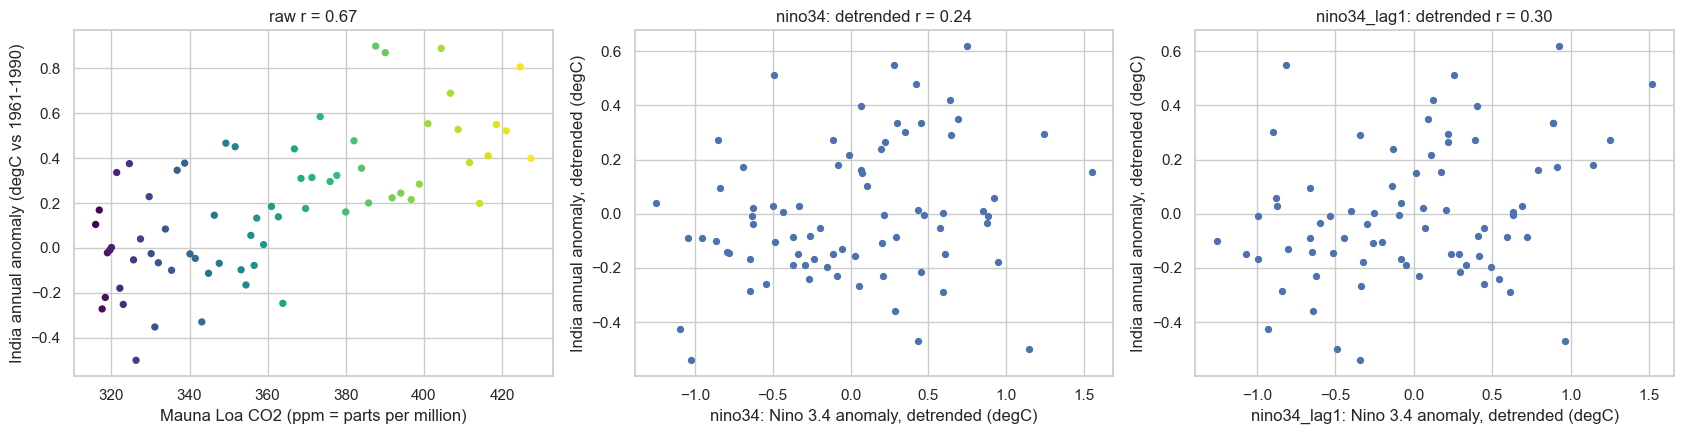

example years:
      india_anom  co2_ppm  nino34_lag1  india_detr  nino_lag1_detr
date                                                              
1971      -0.500   326.32       -0.308      -0.541          -0.340
2010       0.870   390.10        0.286       0.511           0.259
2016       0.889   404.41        1.546       0.481           1.520
2024       0.806   424.61        0.910       0.334           0.885


In [12]:
mlo = pd.read_csv("data/raw/co2_annmean_mlo.txt", comment="#", sep=r"\s+", header=None, names=["year", "mean", "unc"])
co2 = mlo.set_index("year")["mean"].rename("co2_ppm")
nino_m = pd.read_csv("data/raw/detrend.nino34.ascii.txt", sep=r"\s+")
nino_m.columns = [c.strip().upper() for c in nino_m.columns]
nino_m = nino_m[nino_m["ANOM"] > -90]
ng = nino_m.groupby("YR")["ANOM"].agg(["mean", "count"])
nino = ng[ng["count"] == 12]["mean"].rename("nino34")
print("CO2 years:", co2.index.min(), "-", co2.index.max(), "| Nino full years:", nino.index.min(), "-", nino.index.max())

D = annual.rename("india_anom").to_frame().join(co2).join(nino)
D["nino34_lag1"] = nino.reindex(D.index - 1).values

def detrend(s):
    s = s.dropna()
    r = stats.linregress(s.index, s.values)
    return s - (r.intercept + r.slope * s.index)

def corr(a, b):
    j = pd.concat([a, b], axis=1).dropna()
    r, p = stats.pearsonr(j.iloc[:, 0], j.iloc[:, 1])
    return r, p, len(j)

res = []
for x in ["co2_ppm", "nino34", "nino34_lag1"]:
    common = D[["india_anom", x]].dropna()
    r, p, n = corr(common["india_anom"], common[x])
    rd, pd_, nd = corr(detrend(common["india_anom"]), detrend(common[x]))
    res.append({"driver": x, "years": f"{common.index.min()}-{common.index.max()}", "n": n,
                "r raw": r, "p raw": p, "r detrended": rd, "p detrended": pd_})
drv = pd.DataFrame(res).set_index("driver")
print(drv.round(4).to_string())
for x in drv.index:
    SUMMARY[f"r(India anom, {x}) raw / detrended"] = f"{drv.loc[x,'r raw']:.2f} / {drv.loc[x,'r detrended']:.2f}"

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
c1 = D[["india_anom", "co2_ppm"]].dropna()
axes[0].scatter(c1["co2_ppm"], c1["india_anom"], c=c1.index, cmap="viridis", s=18)
axes[0].set_xlabel("Mauna Loa CO2 (ppm = parts per million)"); axes[0].set_ylabel("India annual anomaly (degC vs 1961-1990)")
axes[0].set_title(f"raw r = {drv.loc['co2_ppm','r raw']:.2f}")
for ax, x in zip(axes[1:], ["nino34", "nino34_lag1"]):
    c = D[["india_anom", x]].dropna()
    ax.scatter(detrend(c[x]), detrend(c["india_anom"]), s=18)
    ax.set_xlabel(f"{x}: Nino 3.4 anomaly, detrended (degC)"); ax.set_ylabel("India annual anomaly, detrended (degC)")
    ax.set_title(f"{x}: detrended r = {drv.loc[x,'r detrended']:.2f}")
fig.tight_layout()
save(fig, "07_drivers_scatter"); plt.show()
c = D[["india_anom", "nino34_lag1"]].dropna()
ex = pd.DataFrame({"india_anom": D["india_anom"], "co2_ppm": D["co2_ppm"], "nino34_lag1": D["nino34_lag1"],
                   "india_detr": detrend(c["india_anom"]), "nino_lag1_detr": detrend(c["nino34_lag1"])})
print("example years:"); print(ex.loc[[1971, 2010, 2016, 2024]].round(3).to_string())

### How to read this graph
Each dot is one year. The y-axis is India's yearly anomaly (degC vs 1961-1990).
- **Left:** the x-axis is the CO2 level measured at Mauna Loa in ppm (parts per million). The colour is the year: dark purple = early, yellow = recent.
- **Middle and right:** the x-axis is the Nino 3.4 index in degC (Pacific sea surface warmer + or colder - than normal). The middle panel uses the same year; the right panel uses the previous year.

**Detrended.** Both axes in the middle and right panels are *detrended*: we fit a straight line over time to each series and keep only what is left over. This removes the shared "both go up over time" effect, so only year-to-year ups and downs are compared.

**Worked example.** On the right panel, the dot for 2016 sits at x = 1.520 and y = 0.481. The previous year (2015) had a strong El Nino, and 2016 in India was about 0.48 degC warmer than its long-term trend line would predict.

**What it shows.**
- CO2 and India's temperature rise together: r = 0.67 (for example 2024: 424.61 ppm and +0.806 degC). But after detrending r falls to 0.20, which is not significant. CO2 rises so smoothly that little year-to-year signal is left.
- Last year's El Nino has the clearest year-to-year link: detrended r = 0.30, p = 0.008.

**Why it matters.** For Model 3, CO2 (or time) carries the long-term warming, and last year's Nino helps explain the year-to-year swings. For the dashboard, this explains why a single hot year is not proof on its own: El Nino also plays a part.

**Finding (Drivers):**
- **CO2:** raw r = 0.67 (1959-2025, n = 67). After removing a linear trend from both series, r = 0.20 (p = 0.10, not significant).
  - The raw r mostly reflects that both series rise over time. It is consistent with CO2-driven warming but does not prove it on its own.
  - The detrended value is hard to interpret, because CO2 is nearly a smooth curve.
- **El Nino:** same-year Nino 3.4 has r = 0.17 (p = 0.15) raw and 0.24 (p = 0.037) detrended. Nino lagged 1 year is stronger: r = 0.24 (p = 0.035) raw and **0.30 (p = 0.008) detrended**. Years after an El Nino tend to be warmer in India.
- Both effects are modest. Nino explains only about 9% (0.30^2) of the detrended year-to-year variance.

## 8. Autocorrelation of the monthly all-India anomaly

monthly series length: 900, any NaN: False
raw:       lag1 = 0.386, lag12 = 0.098, lag24 = 0.055
detrended: lag1 = 0.330, lag12 = 0.015, lag24 = -0.030
approx. 95% band for white noise: +/-0.065
saved reports/eda_india/08_acf.png


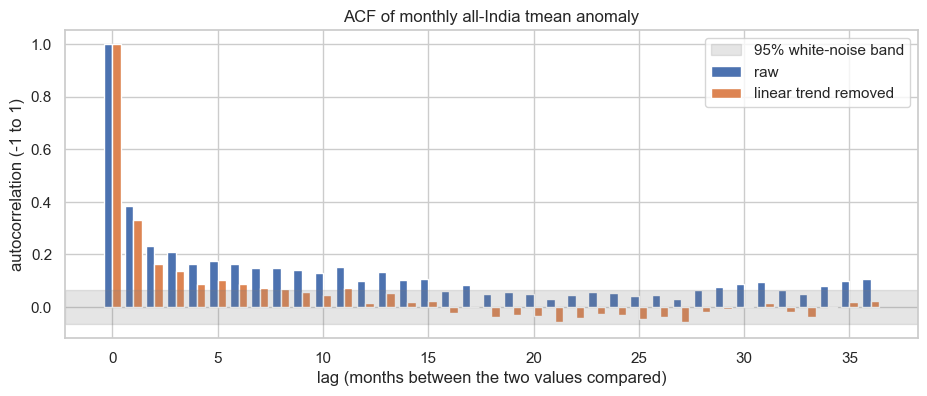

In [13]:
x = monthly.copy()
r = stats.linregress(np.arange(len(x)), x.values)
x_dt = x - (r.intercept + r.slope * np.arange(len(x)))
a_raw = acf(x.values, nlags=36, fft=True)
a_dt = acf(x_dt.values, nlags=36, fft=True)
print(f"monthly series length: {len(x)}, any NaN: {bool(x.isna().any())}")
print(f"raw:       lag1 = {a_raw[1]:.3f}, lag12 = {a_raw[12]:.3f}, lag24 = {a_raw[24]:.3f}")
print(f"detrended: lag1 = {a_dt[1]:.3f}, lag12 = {a_dt[12]:.3f}, lag24 = {a_dt[24]:.3f}")
print(f"approx. 95% band for white noise: +/-{1.96/np.sqrt(len(x)):.3f}")
SUMMARY["Monthly ACF lag1 / lag12 (raw)"] = f"{a_raw[1]:.2f} / {a_raw[12]:.2f}"
SUMMARY["Monthly ACF lag1 / lag12 (detrended)"] = f"{a_dt[1]:.2f} / {a_dt[12]:.2f}"

fig, ax = plt.subplots(figsize=(11, 4))
lags = np.arange(37)
ax.bar(lags - 0.2, a_raw, width=0.4, label="raw")
ax.bar(lags + 0.2, a_dt, width=0.4, label="linear trend removed")
ax.axhspan(-1.96/np.sqrt(len(x)), 1.96/np.sqrt(len(x)), color="grey", alpha=0.2, label="95% white-noise band")
ax.set_xlabel("lag (months between the two values compared)"); ax.set_ylabel("autocorrelation (-1 to 1)"); ax.legend()
ax.set_title("ACF of monthly all-India tmean anomaly")
save(fig, "08_acf"); plt.show()

### How to read this graph
**Autocorrelation.** This is the correlation of a series with a shifted copy of itself. *Lag* = how many months apart the two values are. For example, lag 1 asks: "if this month was warm, was the next month also warm?" It runs from -1 to 1, and 0 means no memory.

**Axes.** The x-axis is the lag in months (0-36). The y-axis is the autocorrelation.
- Blue bars use the monthly all-India anomaly as it is.
- Orange bars use the series after removing its straight-line trend (detrended).
- The grey band (+/-0.065) is how big a value pure chance usually gives. Bars inside it are not meaningful.

**Worked example.** The blue bar at lag 1 is 0.386. When one month is warmer than normal, the next month also tends to be warmer than normal: a moderate link.

**What it shows.** Month-to-month memory is real: lag 1 is 0.386, and still 0.330 after removing the trend. At lag 12 (same month next year) the value is 0.098, but only 0.015 after removing the trend. So the year-to-year link comes almost entirely from the long-term warming.

**Why it matters.** Because neighbouring months are linked, Model 3 must be tested on later years it has never seen, not on randomly picked months. Otherwise the test score will look better than it really is. Simply "copying last month" is a fair baseline to beat.

**Finding (Autocorrelation):**
- The monthly all-India anomaly has lag-1 autocorrelation 0.386. After removing a linear trend it is 0.330, well above the 95% white-noise band (+/-0.065).
- Lag 12 is 0.098 raw and only 0.015 detrended. So the year-to-year memory comes mainly from the long-term trend, while the month-to-month memory is real persistence.
- **For train/test splits:** neighbouring months are not independent, so a random split would leak information. Use a time-ordered split (train on early years, test on later years), ideally with a gap of a few months. A model will also get an easy boost from last month's value; compare against a persistence baseline.

## 9. Summary
Key numbers (collected from the cells above, not typed by hand):

In [14]:
summary_table = pd.Series(SUMMARY, name="value").to_frame()
summary_table.index.name = "metric"
print(summary_table.to_string())

                                                          value
metric                                                         
Rows / cells / months                       322,200 / 358 / 900
% tmean_anom missing                                      2.30%
All-India tmean_anom trend (degC/decade)                  0.081
Warmest year (anom degC)                           2009 (+0.90)
Decade mean 1951-1960 / 2021-2025                 +0.10 / +0.54
Cells with trend (>=60 complete yrs)                        335
Median cell trend tmean (degC/decade)                     0.079
All-India tmax / tmin trend (degC/decade)       +0.088 / +0.075
Season trend DJF (degC/decade)                            0.071
Season trend MAM (degC/decade)                            0.069
Season trend JJAS (degC/decade)                           0.075
Season trend ON (degC/decade)                             0.127
r(India anom, co2_ppm) raw / detrended              0.67 / 0.20
r(India anom, nino34) raw / detrended   

**Decisions for modelling** (each backed by an output above):

1. **Do not fill gaps silently.** 2.30% of tmean_anom is missing, concentrated in Andaman & Nicobar, the far north-east and the far north (up to 69% for one cell). Drop those cells or keep NaN-aware aggregation, and document the choice (Section 1).
2. **Simple (unweighted) all-India mean is fine.** cos(lat) weighting changes annual values by at most 0.017 degC (Section 3).
3. **The target has a clear trend that speeds up after about 1990:** +0.081 degC/decade overall; decade means flat at about 0 to +0.10 until the 1980s, then +0.45 to +0.54 (Section 3). A model needs a trend term or a CO2-like driver, and a straight line will under-fit recent years.
4. **Use a time-based split, not random.** Monthly lag-1 autocorrelation is 0.33-0.39 (Section 8). Benchmark against persistence and against a linear trend.
5. **Candidate inputs:** CO2 (raw r = 0.67 with the annual anomaly) and Nino 3.4 lagged 1 year (detrended r = 0.30, p = 0.008) (Section 7). The same-year Nino link is weaker.
6. **Season matters.** ON warms fastest (+0.127 vs about +0.07 degC/decade for the other seasons; Section 6). Include month or season as an input, or model seasons separately.
7. **Spatial differences are large.** Cell trends range from about 0 (eastern Indo-Gangetic plain) to +0.17 degC/decade (Section 5). A single all-India model hides this. A per-cell model should use only cells with enough complete years (335 of 358).
8. **Risk:** the 1950s have the most missing data (about 6.7%) and only 338 cells, so early-period values are slightly less reliable (Sections 1 and 4).